<a href="https://colab.research.google.com/github/KhytsenkoIgor/python-data-analysis-tasks/blob/main/HW_15_2_%D0%9F%D0%B5%D1%80%D0%B5%D0%B2%D1%96%D1%80%D0%BA%D0%B0_%D1%81%D1%82%D0%B0%D1%82%D0%B8c%D1%82%D0%B8%D1%87%D0%BD%D0%B8%D1%85_%D0%B3%D1%96%D0%BF%D0%BE%D1%82%D0%B5%D0%B7_Z_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Перевірка статиcтичних гіпотез. Z-test.



0. Зчитайте дані з `data.csv` у змінну data, яка має тип pandas.DataFrame. Ми будемо далі працювати з цією змінною.

In [ ]:

import pandas as pd

data = pd.read_csv('data.csv')
data.head()


,Unnamed: 0,data
0,0,17.499453
1,1,19.662399
2,2,7.182823
3,3,29.841625
4,4,9.239386


Запустіть код нижче. Для коректної робити всіх подальших методів дані мають бути у вигляді одновимірного `numpy.ndarray` вектора та мати розмірність (100,). Така розмірність означає, що дані - одновимірні (колонка), якщо б розмірність була (100, 1), то дані сприймаються методами як двовимірні (таблиця), хоча для нас виглядати можуть так само.

In [ ]:
data = data.data.values
data.shape

(100,)

**Завдання 1**. (7 балів)
Зчитані дані - це сума покупок в доларах наших покупців на сайті протягом липня 2025 року.

До цього місяця, ми мали продажі в середньому на чек $20.

Необхідно зʼясувати, чи вийшло у нас статистично значущо **підвищити** середній чек за липень 2025?

Аби дати відповідь - ми проведемо z-test на рівні значущості $\alpha=0.05$ двома способами. В цьому завданні ми будемо виконувати обчислення "вручну" з використанням бібліотек numpy та scipy.stats подібно до прикладу в лекції. Для цього виконайте наступні 7 кроків. Правильне виконання кожного з кроків оцінюється в 1 бал.

1. Запишіть параметри задачі у змінні Python:
    - `sample_mean` - $\bar{x}$, середнє значення в вибірці
    - `population_mean` - $\mu_0$, середнє значення в популяції (тобто те, з яким ми порівнюємо середнє вибіркове значення)
    - `population_std` - $\sigma$, вибіркове стандартне відхилення, яке ми вважаємо, що є рівним ст. відх. популяції, адже маємо достатньо велику вибірку.
    - `sample_size` - $n$, розмір вибірки
    - `alpha` - $\alpha$ рівень значущості
    
    **Увага!** Для обчислення стандартного відхилення маємо скористатись функцією `np.std(your_dataframe, ddof=1)`. Чому так - розбираємо в лекції про t-test.


2. Визначте для цієї задачі:
    - якою є гіпотеза $H_0$
    - якою є альтернативна гіпотеза $H_a$
    - з яким типом тесту ми маємо справу - лівосторонній, правосторонній чи двосторонній.

3. Обчисліть стандартну помилку SE.
4. Розрахуйте z-статистику.
5. Знайдіть критичне z-значення з допомогою бібліотеки stats.
6. Обчисліть p-value з допомогою бібліотеки stats.
7. Прийміть рішення, чи відхиляєте ви гіпотезу $H_0$. Для прийняття рішення зробіть і порівняння z-статистики з критичним значенням, і проаналізуйте p-value.


### Крок 1. Визначення параметрів Z-тесту

**Мета:** перевірити, чи збільшився середній чек покупців у липні 2025 року порівняно з попереднім значенням $20.

**Параметри:**
- `sample_mean` — середній чек у вибірці.
- `population_mean` — попередній середній чек ($20).
- `population_std` — вибіркове стандартне відхилення (`ddof=1`).
- `sample_size` — кількість спостережень.
- `alpha` — рівень значущості (0.05).


In [ ]:

import numpy as np
from scipy import stats

sample_mean = np.mean(data)
population_mean = 20
population_std = np.std(data, ddof=1)
sample_size = len(data)
alpha = 0.05

print(f"Середній чек: {sample_mean:.2f}")
print(f"Попередній середній чек: {population_mean:.2f}")
print(f"Стандартне відхилення: {population_std:.2f}")
print(f"Розмір вибірки: {sample_size}")
print(f"Рівень значущості: {alpha}")


Середній чек: 19.38
Попередній середній чек: 20.00
Стандартне відхилення: 6.25
Розмір вибірки: 100
Рівень значущості: 0.05



### Крок 2. Формулювання статистичних гіпотез

- **H₀: μ ≤ 20** — середній чек не збільшився.
- **Hₐ: μ > 20** — середній чек статистично значущо збільшився.

**Тип тесту:** правосторонній Z-test.

**Рівень значущості:** α = 0.05.



### Крок 3. Розрахунок стандартної помилки (SE)

Стандартна помилка (Standard Error) показує, наскільки вибіркове середнє може відрізнятися від середнього значення популяції через випадковість вибірки.

**Формула:**

$$SE = \frac{\sigma}{\sqrt{n}}$$

де:
- σ — стандартне відхилення вибірки;
- n — розмір вибірки.


In [ ]:

SE = population_std / np.sqrt(sample_size)

print(f"Стандартна помилка (SE): {SE:.4f}")


Стандартна помилка (SE): 0.6254



### Крок 4. Розрахунок Z-статистики

Z-статистика показує, на скільки стандартних помилок вибіркове середнє відхиляється від попереднього середнього чека ($20).

**Формула:**

$$Z = \frac{\bar{x} - \mu_0}{SE}$$

де:
- $\bar{x}$ — середнє значення вибірки;
- $\mu_0$ — попередній середній чек;
- $SE$ — стандартна помилка.


In [ ]:

z_stat = (sample_mean - population_mean) / SE

print(f"Z-статистика: {z_stat:.4f}")


Z-статистика: -0.9953



### Крок 5. Визначення критичного Z-значення

Для правостороннього Z-тесту з рівнем значущості $\alpha = 0.05$ визначаємо критичне значення за допомогою `stats.norm.ppf()`.

**Формула:**

$$Z_{crit} = \Phi^{-1}(1-\alpha)$$

Якщо $Z > Z_{crit}$, відхиляємо нульову гіпотезу H₀.


In [ ]:

z_critical = stats.norm.ppf(1 - alpha)

print(f"Критичне Z-значення: {z_critical:.4f}")


Критичне Z-значення: 1.6449



### Крок 6. Розрахунок p-value

p-value — це ймовірність отримати Z-статистику не меншу за спостережувану за умови, що нульова гіпотеза H₀ правильна.

Оскільки тест правосторонній, використовуємо функцію `stats.norm.sf()`.

**Формула:**

$$p\text{-value} = 1 - \Phi(Z)$$

Якщо p-value < 0.05, відхиляємо H₀.


In [ ]:

p_value = stats.norm.sf(z_stat)

print(f"p-value: {p_value:.4f}")


p-value: 0.8402



### Візуалізація результатів Z-тесту

Побудуємо два графіки для правостороннього Z-тесту з рівнем значущості α = 0.05.

1. **Критична область та Z-статистика** — показує розташування нашої Z-статистики відносно критичної області.
2. **Розташування вибіркових середніх** — показує фактичний середній чек відносно попереднього значення 20 USD та критичної межі.

Мета — наочно перевірити, чи потрапляє отриманий результат до області відхилення H₀.


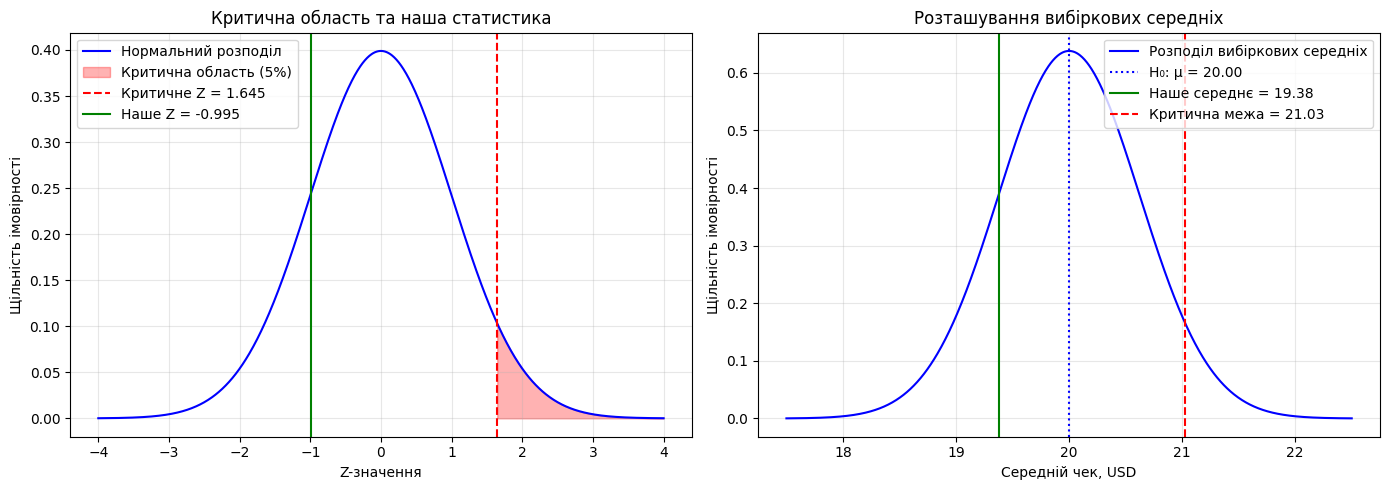

In [ ]:

import matplotlib.pyplot as plt

x = np.linspace(-4, 4, 1000)
y = stats.norm.pdf(x)

critical_mean = population_mean + z_critical * SE

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Графік 1. Критична область та Z-статистика
axes[0].plot(x, y, color='blue', label='Нормальний розподіл')
axes[0].fill_between(x, y, where=x >= z_critical,
                     color='red', alpha=0.3, label='Критична область (5%)')
axes[0].axvline(z_critical, color='red', linestyle='--',
                label=f'Критичне Z = {z_critical:.3f}')
axes[0].axvline(z_stat, color='green',
                label=f'Наше Z = {z_stat:.3f}')
axes[0].set_title('Критична область та наша статистика')
axes[0].set_xlabel('Z-значення')
axes[0].set_ylabel('Щільність імовірності')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Графік 2. Розташування вибіркових середніх
means = population_mean + x * SE
density = stats.norm.pdf(means, population_mean, SE)

axes[1].plot(means, density, color='blue',
             label='Розподіл вибіркових середніх')
axes[1].axvline(population_mean, color='blue', linestyle=':',
                label=f'H₀: μ = {population_mean:.2f}')
axes[1].axvline(sample_mean, color='green',
                label=f'Наше середнє = {sample_mean:.2f}')
axes[1].axvline(critical_mean, color='red', linestyle='--',
                label=f'Критична межа = {critical_mean:.2f}')
axes[1].set_title('Розташування вибіркових середніх')
axes[1].set_xlabel('Середній чек, USD')
axes[1].set_ylabel('Щільність імовірності')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



### Крок 7. Перевірка гіпотези та висновок

**Результати Z-тесту:**

- H₀: μ ≤ 20 — середній чек не збільшився.
- Hₐ: μ > 20 — середній чек збільшився.
- Рівень значущості α = 0.05.
- Z-статистика = −0.9953.
- Критичне Z-значення = 1.6449.
- p-value = 0.8402.

**Перевірка:**

1. Z = −0.9953 < 1.6449 — не відхиляємо H₀.
2. p-value = 0.8402 > 0.05 — не відхиляємо H₀.


**Висновок:** на рівні значущості 5% немає статистичних доказів підвищення середнього чека в липні 2025 року. Фактичний середній чек становив 19.38 USD проти попередніх 20 USD.



In [ ]:

print(f"Z-статистика: {z_stat:.4f}")
print(f"Критичне Z-значення: {z_critical:.4f}")
print(f"p-value: {p_value:.4f}")

if z_stat > z_critical and p_value < alpha:
    print("Відхиляємо H₀. Середній чек статистично значущо збільшився.")
else:
    print("Не відхиляємо H₀. Статистично значущого збільшення середнього чека не виявлено.")


Z-статистика: -0.9953
Критичне Z-значення: 1.6449
p-value: 0.8402
Не відхиляємо H₀. Статистично значущого збільшення середнього чека не виявлено.


**Завдання 2.** (3 бали)
Виконайте обчислення z-test з використанням бібліотеки statsmodels.

Отримайте z-статистику та р-значення.

Виведіть p-значення та зробіть висновок, чи ми маємо достатньо доказів, аби стверджувати, що середній чек зріс.

Чи зійшлись значення z-статистику та р-значення в цьому завданні з попередніми обчисленнями?


###  Перевірка Z-test за допомогою statsmodels

**Мета:** перевірити, чи статистично значущо збільшився середній чек покупців у липні 2025 року.

**Гіпотези:**
- H₀: μ ≤ 20 — середній чек не збільшився.
- Hₐ: μ > 20 — середній чек збільшився.

**Тип тесту:** правосторонній Z-test.

**Рівень значущості:** α = 0.05.

Для розрахунку використовуємо функцію `ztest()` із бібліотеки `statsmodels`.


In [ ]:

from statsmodels.stats.weightstats import ztest

z_stat_sm, p_value_sm = ztest(data, value=20, alternative='larger')

print(f"Z-статистика: {z_stat_sm:.4f}")
print(f"p-value: {p_value_sm:.4f}")

if p_value_sm < alpha:
    print("Відхиляємо H₀. Середній чек статистично значущо збільшився.")
else:
    print("Не відхиляємо H₀. Статистично значущого збільшення середнього чека не виявлено.")

print(f"Z-статистики збігаються: {np.isclose(z_stat_sm, z_stat)}")
print(f"p-value збігаються: {np.isclose(p_value_sm, p_value)}")


Z-статистика: -0.9953
p-value: 0.8402
Не відхиляємо H₀. Статистично значущого збільшення середнього чека не виявлено.
Z-статистики збігаються: True
p-value збігаються: True



### Висновок

За результатами Z-тесту з використанням `statsmodels`:

- Z-статистика = −0.9953.
- p-value = 0.8402.
- Рівень значущості α = 0.05.

Оскільки p-value > 0.05, **не відхиляємо H₀**.

Статистично значущого підвищення середнього чека у липні 2025 року не виявлено.

**Порівняння:** результати Z-статистики та p-value повністю збігаються з обчисленнями в завданні 1.



### Візуалізація результатів Z-тесту: NumPy/SciPy vs Statsmodels

Порівняємо результати двох способів розрахунку Z-тесту:

- **NumPy/SciPy** — ручний розрахунок (завдання 1).
- **Statsmodels** — автоматизований розрахунок (завдання 2).

Порівнюємо Z-статистику та p-value за рівня значущості α = 0.05.


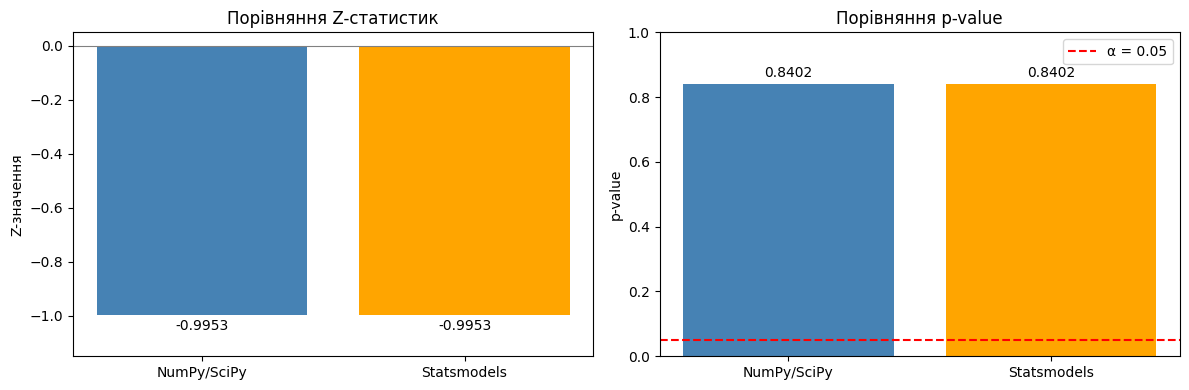

In [ ]:

import matplotlib.pyplot as plt

methods = ['NumPy/SciPy', 'Statsmodels']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Порівняння Z-статистик
axes[0].bar(methods, [z_stat, z_stat_sm], color=['steelblue', 'orange'])
axes[0].set_title('Порівняння Z-статистик')
axes[0].set_ylabel('Z-значення')
axes[0].bar_label(axes[0].containers[0], fmt='%.4f', padding=3)
axes[0].axhline(0, color='gray', linewidth=0.8)

# Порівняння p-value
axes[1].bar(methods, [p_value, p_value_sm], color=['steelblue', 'orange'])
axes[1].axhline(alpha, color='red', linestyle='--', label='α = 0.05')
axes[1].set_title('Порівняння p-value')
axes[1].set_ylabel('p-value')
axes[1].bar_label(axes[1].containers[0], fmt='%.4f', padding=3)
axes[1].legend()

axes[0].set_ylim(-1.15, 0.05)
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()



### Висновок за результатами візуалізації

Обидва методи розрахунку Z-тесту дали однакові результати:

- Z-статистика = −0.9953.
- p-value = 0.8402.

Значення p-value перевищує рівень значущості 0.05.

**Висновок:** результати NumPy/SciPy та Statsmodels збігаються. Статистично значущого підвищення середнього чека не виявлено, тому H₀ не відхиляємо.
